# MNIST Digit Prediction

Train a small neural network to recognise handwritten digits (0–9), then use it to predict new images.

**Architecture:** `784 → 128 → 64 → 10`, a plain fully connected network. Every neuron is easy to inspect, which sets up the slow-motion activation visualizer later.

In [1]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.14.1 | device: mps


## 1. Load the data
60,000 training images and 10,000 test images, each 28×28 grayscale. Downloaded once into `data/`.

In [2]:
from model import DigitNet, MEAN, STD, transform

train_set = datasets.MNIST("data", train=True, download=True, transform=transform)
test_set = datasets.MNIST("data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000)

print(f"train: {len(train_set)} | test: {len(test_set)}")

train: 60000 | test: 10000


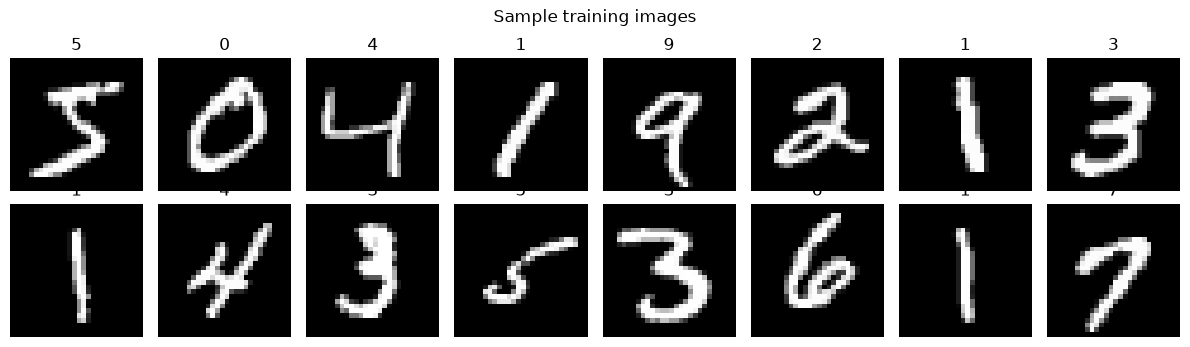

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, range(16)):
    img, label = train_set[i]
    ax.imshow(img.squeeze() * STD + MEAN, cmap="gray")
    ax.set_title(label)
    ax.axis("off")
plt.suptitle("Sample training images")
plt.tight_layout()
plt.show()

## 2. Define the model

In [4]:
# the network itself is in model.py
model = DigitNet().to(device)
print(model)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

DigitNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (out): Linear(in_features=64, out_features=10, bias=True)
)
parameters: 109,386


## 3. Train

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 5

def evaluate(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(loader.dataset)

history = {"loss": [], "test_acc": []}
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
    history["loss"].append(total_loss / len(train_set))
    history["test_acc"].append(evaluate(model, test_loader))
    print(f"epoch {epoch}: loss {history['loss'][-1]:.4f} | test accuracy {history['test_acc'][-1]:.2%}")

epoch 1: loss 0.3153 | test accuracy 95.28%


epoch 2: loss 0.1267 | test accuracy 96.61%


epoch 3: loss 0.0897 | test accuracy 97.09%


epoch 4: loss 0.0672 | test accuracy 97.28%


epoch 5: loss 0.0527 | test accuracy 97.66%


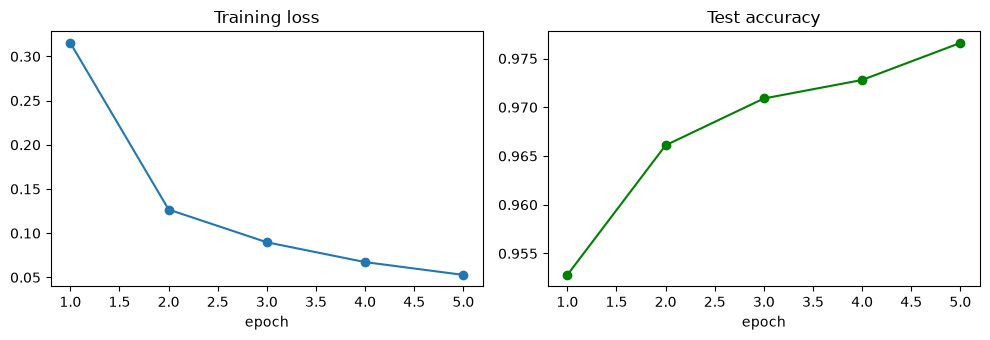

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
epochs = range(1, EPOCHS + 1)
ax1.plot(epochs, history["loss"], marker="o"); ax1.set_title("Training loss"); ax1.set_xlabel("epoch")
ax2.plot(epochs, history["test_acc"], marker="o", color="green"); ax2.set_title("Test accuracy"); ax2.set_xlabel("epoch")
plt.tight_layout()
plt.show()

## 4. Predict
Give the model an image it has never seen and look at how confident it is about each digit.

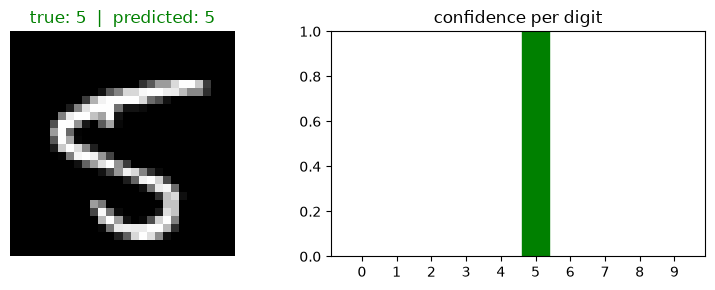

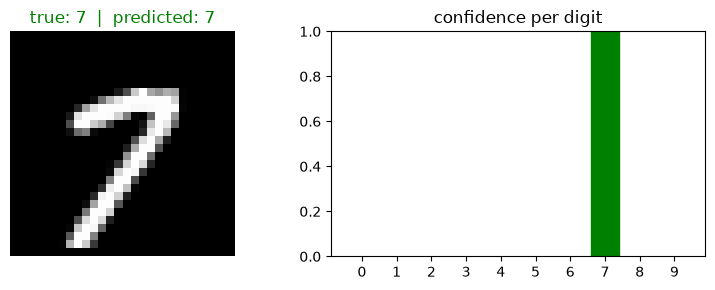

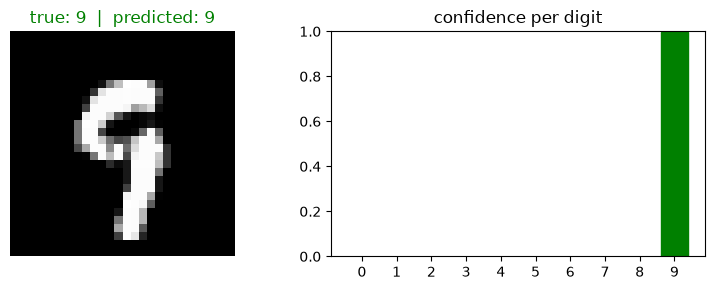

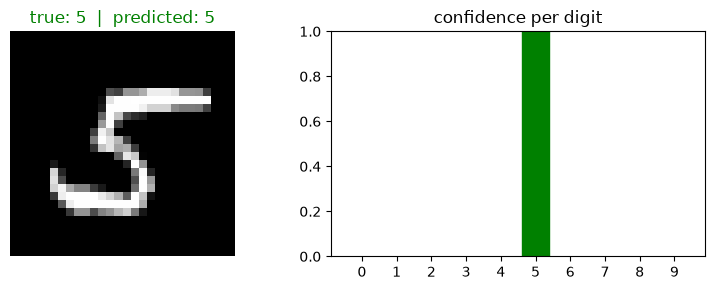

In [7]:
def predict(img):
    """img: normalized tensor of shape (1, 28, 28). Returns (digit, probabilities)."""
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(img.unsqueeze(0).to(device)), dim=1).squeeze().cpu()
    return probs.argmax().item(), probs

def show_prediction(idx):
    img, label = test_set[idx]
    digit, probs = predict(img)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
    ax1.imshow(img.squeeze() * STD + MEAN, cmap="gray")
    ax1.set_title(f"true: {label}  |  predicted: {digit}", color="green" if digit == label else "red")
    ax1.axis("off")
    bars = ax2.bar(range(10), probs.numpy(), color="lightgray")
    bars[digit].set_color("green" if digit == label else "red")
    ax2.set_xticks(range(10)); ax2.set_ylim(0, 1); ax2.set_title("confidence per digit")
    plt.tight_layout()
    plt.show()

for idx in np.random.default_rng(0).choice(len(test_set), 4, replace=False):
    show_prediction(int(idx))

## 5. Where it gets it wrong
The mistakes are usually digits a human would hesitate on too.

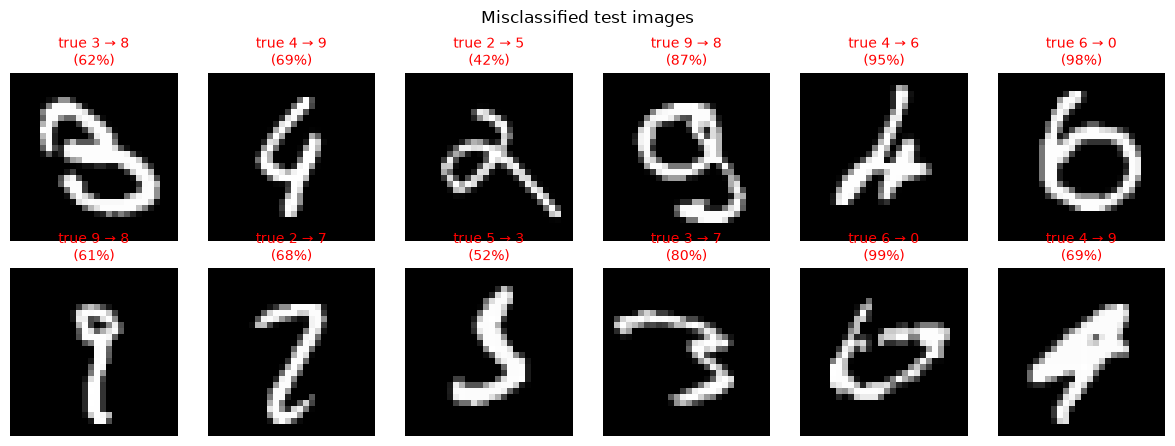

In [8]:
model.eval()
wrong = []
with torch.no_grad():
    for i in range(len(test_set)):
        img, label = test_set[i]
        digit, probs = predict(img)
        if digit != label:
            wrong.append((img, label, digit, probs[digit].item()))
        if len(wrong) == 12:
            break

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, (img, label, digit, conf) in zip(axes.flat, wrong):
    ax.imshow(img.squeeze() * STD + MEAN, cmap="gray")
    ax.set_title(f"true {label} → {digit}\n({conf:.0%})", color="red", fontsize=10)
    ax.axis("off")
plt.suptitle("Misclassified test images")
plt.tight_layout()
plt.show()

## 6. Save the model

In [9]:
import os
os.makedirs("models", exist_ok=True)
torch.save(model.state_dict(), "models/digit_net.pt")
print("saved to models/digit_net.pt")

saved to models/digit_net.pt
